# 01. Monthly data preparation and inspection
Notebook-only evidence for the inflation forecasting review. Run with the project's `.venv` Python kernel. All figures and inspection tables are retained below. The source files remain unchanged.

**Purpose:** prepare one national monthly dataset for forecasting Philippine headline inflation. Target values are already year-on-year percentages. Predictors have different units and are not added together. The companion model notebook explains the shared sample, lagging and chronological evaluation.

The input files are supplied data, not execution instructions. They have not been independently authenticated. Original release dates/vintages were not provided.

In [1]:
from pathlib import Path
import sys,json,hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
get_ipython().run_line_magic('matplotlib','inline')
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
OUT=ROOT/'artifacts/model_review'
OUT.mkdir(parents=True,exist_ok=True)
from src.prepare import prepare
monthly,manifest=prepare()
print('Kernel:',sys.executable)
display(monthly.head(),monthly.tail())

Kernel: C:\Users\Luzan\Documents\Elec 4\.venv\Scripts\python.exe


,inflation,exchange_rate,m3,policy_rate,m3_growth
date,,,,,
2010-01-01,3.9,46.027600,3.910182e+06,4.0,NaN
2010-02-01,3.9,46.311600,3.939374e+06,4.0,NaN
2010-03-01,3.9,45.742478,3.991470e+06,4.0,NaN
2010-04-01,4.0,44.626579,4.025107e+06,4.0,NaN
2010-05-01,3.9,45.597105,4.046092e+06,4.0,NaN


,inflation,exchange_rate,m3,policy_rate,m3_growth
date,,,,,
2026-04-01,7.2,60.291316,2.034729e+07,4.50,12.241121
2026-05-01,6.8,61.441000,2.060313e+07,4.50,12.798545
2026-06-01,6.4,61.251286,2.053946e+07,4.75,10.739871
2026-07-01,6.2,61.596261,2.051968e+07,4.75,10.295775
2026-08-01,6.1,61.328105,NaN,5.00,NaN


## Source mapping and preparation decisions
| Input | Decision | Reason |
|---|---|---|
| Two inflation CSVs | Read semicolon-separated data after descriptive headers; select PHILIPPINES / 0 - ALL ITEMS | Keep a national all-items target on the same stated 2018=100 basis |
| pesodollar.xlsx | Select monthly Average, carry year labels down during parsing | Avoid substituting daily or end-of-period values |
| MonetaryPolicyDecisions.xlsx | Extract numeric first policy-rate clause; choose last decision in month and carry earlier known rate forward | Policy decisions are events, not a complete monthly table |
| dcs_srf.xlsx | Select M3 level row 25, parse datetime and suffixed provisional/revised month labels | Avoid confusing M3 with M4, M3/GDP or a growth row |
| Derived M3 growth | 100*(M3[t]/M3[t-12]-1), with no fill | Express annual money-supply growth using a complete prior year |
| ms.xls | Retain raw archive, exclude from primary analysis | Its history ends December 2005, before the chosen primary sample |

Blank '..' inflation cells are missing, not zero. No target or M3 interpolation is used. July 2026 is the common primary endpoint; August M3 is unavailable. Unemployment was not supplied. Exact policy effective dates and the 2016 policy framework change require manual review.

In [2]:
coverage=pd.DataFrame(manifest['coverage']).T
display(coverage)
review=pd.read_csv(ROOT/'data/processed/policy_review.csv')
display(review)
print('Nonnumeric hold decisions requiring review:',len(review))
display(Markdown('**Interpretation:** the five listed 2011 descriptions state that rates were held without repeating a numeric rate. The parser carries the last earlier numeric decision forward. These records are preserved for review, not silently discarded. M3 growth has twelve unavailable starting months by construction.'))

,start,end,missing
inflation,2010-01-01 00:00:00,2026-08-01 00:00:00,0
exchange_rate,2010-01-01 00:00:00,2026-08-01 00:00:00,0
m3,2010-01-01 00:00:00,2026-07-01 00:00:00,1
policy_rate,2010-01-01 00:00:00,2026-08-01 00:00:00,0
m3_growth,2011-01-01 00:00:00,2026-07-01 00:00:00,13


,row,date,description
0,119,2011-12-01,The Monetary Board decided to maintain the ove...
1,120,2011-10-20,The Monetary Board decided to maintain the ove...
2,121,2011-09-08,The Monetary Board decided to keep the overnig...
3,122,2011-07-28,The Monetary Board decided to maintain the BSP...
4,123,2011-06-16,The Monetary Board decided to keep policy rate...


Nonnumeric hold decisions requiring review: 5


**Interpretation:** the five listed 2011 descriptions state that rates were held without repeating a numeric rate. The parser carries the last earlier numeric decision forward. These records are preserved for review, not silently discarded. M3 growth has twelve unavailable starting months by construction.

## Validation of grain, continuity and transformation
Each analytical row is one national reference month. The primary sample should have 199 rows from January 2010 through July 2026 before growth and lag losses. Source hashes verify the supplied file versions, not their publication authenticity.

In [3]:
primary=monthly.loc['2010-01-01':'2026-07-01']
assert len(primary)==199 and primary.index.is_unique
assert primary.index.equals(pd.date_range('2010-01-01','2026-07-01',freq='MS',name='date'))
assert primary[['inflation','exchange_rate','m3','policy_rate']].notna().all().all()
assert primary.m3.gt(0).all()
assert np.allclose(primary.m3_growth.iloc[12:],primary.m3.pct_change(12,fill_method=None).iloc[12:]*100)
for f in manifest['files']:
    assert hashlib.sha256((ROOT/'data/raw'/f['file']).read_bytes()).hexdigest()==f['sha256']
display(primary.describe().T.round(3))
example=pd.DataFrame({'M3 this month':primary.m3,'M3 twelve months earlier':primary.m3.shift(12),'derived YoY growth (%)':primary.m3_growth}).tail(6)
display(example.round(3))
print('PASS: 199 continuous primary months, source hashes, complete core series and M3 growth reconciliation.')

,count,mean,std,min,25%,50%,75%,max
inflation,199.0,3.391000e+00,1.760,-0.400,2.250,3.200000e+00,4.200000e+00,8.700000e+00
exchange_rate,199.0,4.970400e+01,5.482,40.672,44.619,4.986300e+01,5.397500e+01,6.159600e+01
m3,199.0,1.106604e+07,4989918.274,3910181.904,6958286.345,1.091909e+07,1.536012e+07,2.060313e+07
policy_rate,199.0,3.995000e+00,1.199,2.000,3.125,4.000000e+00,4.500000e+00,6.500000e+00
m3_growth,187.0,1.085000e+01,6.426,4.643,6.965,8.884000e+00,1.251000e+01,3.796700e+01


,M3 this month,M3 twelve months earlier,derived YoY growth (%)
date,,,
2026-02-01,1.984521e+07,1.798709e+07,10.330
2026-03-01,2.038250e+07,1.818087e+07,12.110
2026-04-01,2.034729e+07,1.812820e+07,12.241
2026-05-01,2.060313e+07,1.826542e+07,12.799
2026-06-01,2.053946e+07,1.854748e+07,10.740
2026-07-01,2.051968e+07,1.860423e+07,10.296


PASS: 199 continuous primary months, source hashes, complete core series and M3 growth reconciliation.


## Embedded exploratory figures
Separate panels retain original units. Missingness is shown explicitly instead of being turned into zero-valued observations.

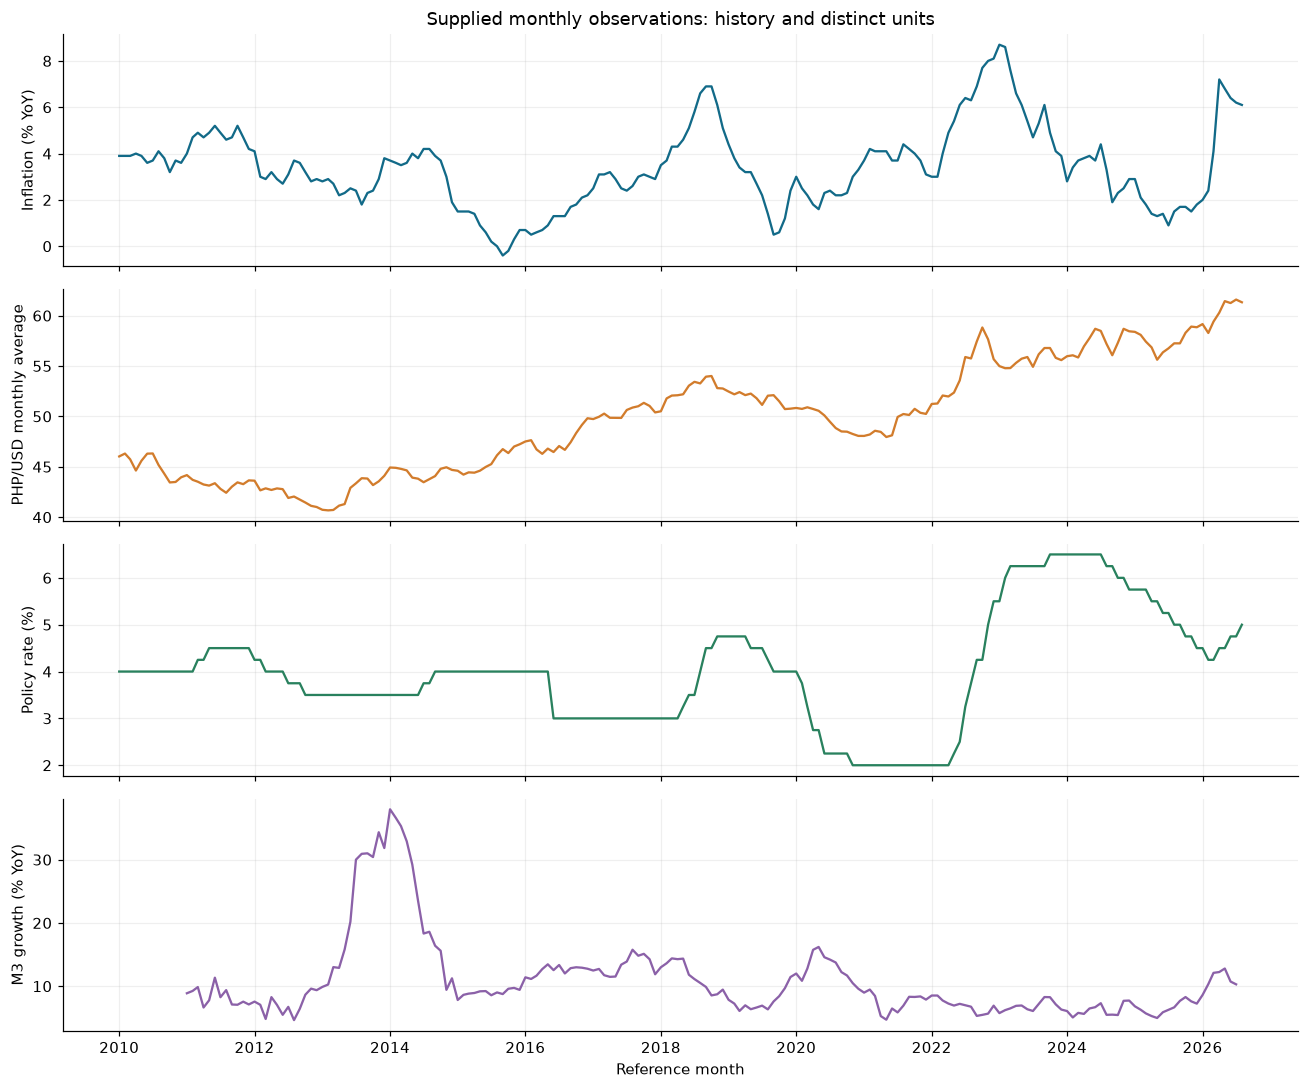

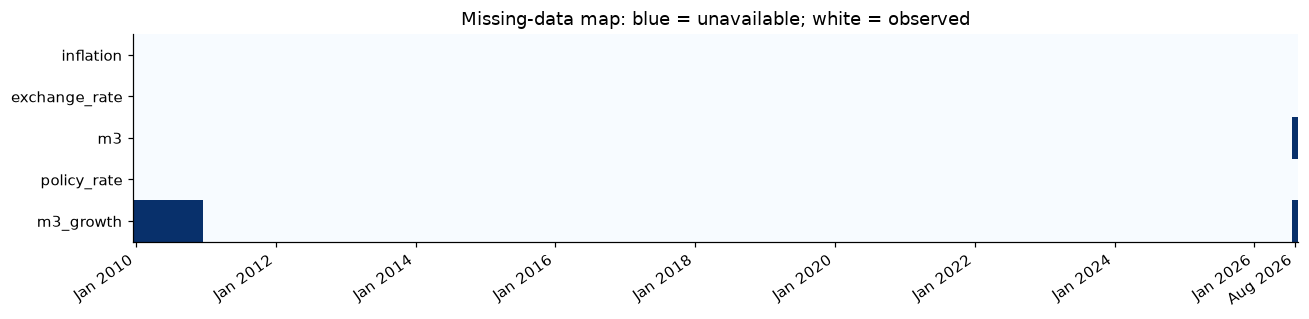

**Interpretation:** historical inflation varies across distinct episodes. Series on different scales cannot be compared by raw line height. The missing-data map identifies the expected M3-growth warm-up and the absent August M3 observation; no artificial values are introduced to close these gaps.

In [4]:
fig,axes=plt.subplots(4,1,figsize=(12,10),sharex=True)
for ax,col,label,color in zip(axes,['inflation','exchange_rate','policy_rate','m3_growth'],
    ['Inflation (% YoY)','PHP/USD monthly average','Policy rate (%)','M3 growth (% YoY)'],['#126a88','#d27c2c','#29815e','#8b61a8']):
    ax.plot(monthly.index,monthly[col],color=color,lw=1.5)
    ax.set_ylabel(label)
    ax.grid(alpha=.2)
axes[0].set_title('Supplied monthly observations: history and distinct units')
axes[-1].set_xlabel('Reference month')
fig.tight_layout()
fig.savefig(OUT/'preparation_series.png',dpi=150,bbox_inches='tight')
plt.show()
plt.close(fig)
fig,ax=plt.subplots(figsize=(12,3))
ax.imshow(monthly.isna().T.values,aspect='auto',interpolation='nearest',cmap='Blues',vmin=0,vmax=1)
ax.set_yticks(range(len(monthly.columns)),monthly.columns)
ticks=list(range(0,len(monthly),24))+[len(monthly)-1]
ax.set_xticks(ticks,[monthly.index[i].strftime('%b %Y') for i in ticks],rotation=35,ha='right')
ax.set_title('Missing-data map: blue = unavailable; white = observed')
fig.tight_layout()
fig.savefig(OUT/'preparation_missingness.png',dpi=150,bbox_inches='tight')
plt.show()
plt.close(fig)
display(Markdown('**Interpretation:** historical inflation varies across distinct episodes. Series on different scales cannot be compared by raw line height. The missing-data map identifies the expected M3-growth warm-up and the absent August M3 observation; no artificial values are introduced to close these gaps.'))

## Provenance and next step
Proceed to **02_model_development.ipynb** for training-only diagnostics, candidate definitions, actual fitting, chronological validation, per-horizon results and residual review. Original release availability, revisions, policy-rate definition changes and possible structural breaks remain research limitations.

In [5]:
display(pd.DataFrame(manifest['files']))
print(chr(10).join(manifest['notes']))
print('Prepared dataset: data/processed/monthly.csv')

,file,sha256,bytes
0,Dataset-11995-2018.csv,b02d6827f33ef679121e2fa3b773157977bf9bbb2d3229...,4553
1,Dataset-12019-2026.csv,03d91d90472d2af5806261f44f79db91012a62e0f0e2a2...,1629
2,dcs_srf.xlsx,d4f502ffc57c248e82f9c97726ce91d62cf936e2409abc...,280249
3,MonetaryPolicyDecisions.xlsx,9837b1f40cc0b59b27193f641a89c962ee70a0c4c3e019...,76050
4,ms.xls,1f5f98566c016c0ab52197d0c690855bbbe0c888131697...,289280
5,pesodollar.xlsx,077dccd10c75b255b306f3d2973f3b1b43986b549bcff9...,205854


User-supplied source files; not independently authenticated.
Source vintage is the supplied file hash; original release dates are unavailable.
Policy rate extracted from decision text: review policy_review.csv before research use.
ms.xls retained for reconciliation; primary M3 comes from DCS level row 25.
Unemployment not supplied.
Model experiment ends July 2026; August inflation is available for display.
Prepared dataset: data/processed/monthly.csv
